# 01 - Data Preparation: CICIoMT2024 (WiFi + MQTT)

Prepares one shared dataset for all models in the project. Baselines are in `models/baselines/pca_baseline.ipynb`.

**Source:** cleaned version of CICIoMT2024 on Zenodo (`wifi_mqtt_clean.parquet`, ~9.1M rows).

**Outputs (saved to `DATA_DIR`):**

| File | Content |
|---|---|
| `train.npz` | `X`: benign traffic only (training) |
| `val.npz` | `X`: benign traffic only (threshold + early stopping) |
| `test.npz` | `X`, `y` (0 = benign, 1 = attack), `attack_type`, `category` |
| `scaler.pkl` | MinMaxScaler fitted on train only |
| `config.json` | feature list, log-transformed columns, preprocessing decisions |
| `figures/` | EDA plots |

In [1]:
# ======================= Config =======================
DATA_DIR = "/content/drive/MyDrive/IoMT_project/data"   # shared project folder
WORK_DIR = "/content/ciciomt"                            # temporary download folder
PARQUET_PATH = None      # None = download from Zenodo

SEED = 42
N_TRAIN = 150_000        # benign samples for training
N_VAL = 30_000           # benign samples for validation
N_TEST_BENIGN = 45_000   # upper limit; all 37,607 benign test rows are used
ATTACK_PER_TYPE = 300    # samples per attack type in test (~12% attacks overall)

DROP_COLS = []           # columns to drop manually (see leakage check)
LABEL_COL = "label"      # column with the traffic type (None = auto-detect)
SPLIT_COL = "split"      # original train/test split column (None = auto-detect)
PROFILING_AS_TRAIN = False  # profiling traffic differs from test-scenario benign traffic

In [2]:
import os, re, json, glob, zipfile, subprocess, urllib.request
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import matplotlib.pyplot as plt

try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    print("Not running on Colab, skipping Drive mount")

os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(os.path.join(DATA_DIR, "figures"), exist_ok=True)
os.makedirs(WORK_DIR, exist_ok=True)
rng = np.random.default_rng(SEED)

Mounted at /content/drive


## 1. Download
The parquet file is inside `Core Processed Data.zip` (~250 MB).

In [3]:
ZIP_URL = "https://zenodo.org/records/19452870/files/Core%20Processed%20Data.zip?download=1"

if PARQUET_PATH is None:
    found = glob.glob(os.path.join(WORK_DIR, "**", "wifi*mqtt*clean*.parquet"), recursive=True)
    if not found:
        zip_path = os.path.join(WORK_DIR, "core.zip")
        if not os.path.exists(zip_path):
            print("Downloading...")
            try:
                subprocess.run(["wget", "-q", "--show-progress", "-c", ZIP_URL, "-O", zip_path], check=True)
            except (FileNotFoundError, subprocess.CalledProcessError):
                urllib.request.urlretrieve(ZIP_URL, zip_path)
        with zipfile.ZipFile(zip_path) as z:
            print("Archive contents:")
            for n in z.namelist():
                print("  ", n)
            z.extractall(WORK_DIR)
        found = glob.glob(os.path.join(WORK_DIR, "**", "wifi*mqtt*clean*.parquet"), recursive=True)
    if not found:
        raise FileNotFoundError("WiFi/MQTT parquet file not found in the archive, set PARQUET_PATH manually")
    PARQUET_PATH = found[0]

print("PARQUET_PATH =", PARQUET_PATH)

Downloading...
Archive contents:
   bluetooth_clean.parquet
   cleaning_summary.csv
   wifi_mqtt_clean.parquet
PARQUET_PATH = /content/ciciomt/wifi_mqtt_clean.parquet


## 2. Inspect columns and detect the label column

In [4]:
pf = pq.ParquetFile(PARQUET_PATH)
schema = pf.schema_arrow
print(f"Rows: {pf.metadata.num_rows:,} | Columns: {len(schema)}\n")

def is_text(t):
    return pa.types.is_string(t) or pa.types.is_large_string(t) or pa.types.is_dictionary(t)

text_cols = [f.name for f in schema if is_text(f.type)]
num_cols  = [f.name for f in schema if pa.types.is_integer(f.type) or pa.types.is_floating(f.type)
             or pa.types.is_boolean(f.type)]
other     = [f.name for f in schema if f.name not in text_cols + num_cols]
print("Text columns:", text_cols)
print("Numeric columns:", len(num_cols), num_cols)
if other: print("Ignored columns (other types):", other)

uniques = {}
for c in text_cols:
    vc = pq.read_table(PARQUET_PATH, columns=[c]).column(c).combine_chunks()
    if pa.types.is_dictionary(vc.type):
        vc = vc.cast(pa.string())
    uniques[c] = {d["values"]: d["counts"] for d in vc.value_counts().to_pylist()}
    print(f"\n{c}: {len(uniques[c])} unique values, most common:")
    for k, v in sorted(uniques[c].items(), key=lambda kv: -kv[1])[:8]:
        print(f"    {k!r:45} {v:>12,}")

def looks_like_split(vals):
    return 1 < len(vals) <= 4 and all(str(v).lower() in {"train", "test", "val", "validation", "profiling"} for v in vals)

def norm_split(s):
    s = s.astype(str).str.lower().replace({"validation": "train", "val": "train"})
    return s.replace({"profiling": "train" if PROFILING_AS_TRAIN else "skip"})

if SPLIT_COL is None:
    cands = [c for c in text_cols if looks_like_split(uniques[c])]
    SPLIT_COL = cands[0] if cands else None

if LABEL_COL is None:
    cands = [c for c in text_cols if c != SPLIT_COL and any("benign" in str(v).lower() for v in uniques[c])]
    if not cands:
        raise ValueError("No column contains 'Benign', set LABEL_COL manually")
    named = [c for c in cands if c.lower() in {"label", "labels", "class", "attack"}]
    LABEL_COL = named[0] if named else min(cands, key=lambda c: len(uniques[c]))

assert LABEL_COL in text_cols, f"{LABEL_COL!r} is not a text column"
if SPLIT_COL is not None:
    assert SPLIT_COL in text_cols, f"{SPLIT_COL!r} is not a text column"

print(f"\nLABEL_COL = {LABEL_COL!r} | SPLIT_COL = {SPLIT_COL!r}")
FEATURES_ALL = [c for c in num_cols if c != LABEL_COL]

Rows: 9,128,910 | Columns: 50

Text columns: ['label', 'source_file', 'protocol', 'split']
Numeric columns: 46 ['header_length', 'protocol_type', 'duration', 'rate', 'srate', 'drate', 'fin_flag_number', 'syn_flag_number', 'rst_flag_number', 'psh_flag_number', 'ack_flag_number', 'ece_flag_number', 'cwr_flag_number', 'ack_count', 'syn_count', 'fin_count', 'rst_count', 'http', 'https', 'dns', 'telnet', 'smtp', 'ssh', 'irc', 'tcp', 'udp', 'dhcp', 'arp', 'icmp', 'igmp', 'ipv', 'llc', 'tot_sum', 'min', 'max', 'avg', 'std', 'tot_size', 'iat', 'number', 'magnitue', 'radius', 'covariance', 'variance', 'weight', 'time_to_live']

label: 19 unique values, most common:
    'DDoS UDP Flood'                                 1,998,026
    'DDoS ICMP Flood'                                1,886,518
    'DDoS TCP Flood'                                   987,062
    'DDoS SYN Flood'                                   974,343
    'DoS UDP Flood'                                    704,503
    'Benign'        

## 3. Normalize attack names and look at the class distribution

split                      skip    test    train  category
type                                                      
Benign                   361081   37607   192732    Benign
DDoS ICMP Flood               0  349698  1536820      DDoS
DDoS SYN Flood                0  172397   801946      DDoS
DDoS TCP Flood                0  182597   804465      DDoS
DDoS UDP Flood                0  362070  1635956      DDoS
DoS UDP Flood                 0  137553   566950       DoS
DoS ICMP Flood                0   98432   416292       DoS
DoS SYN Flood                 0   98595   441903       DoS
DoS TCP Flood                 0   82096   380384       DoS
MQTT DDoS Connect Flood       0   41916   173036      MQTT
MQTT DDoS Publish Flood       0    8416    27623      MQTT
MQTT DoS Connect Flood        0    3131    12773      MQTT
MQTT DoS Publish Flood        0    8505    44376      MQTT
MQTT Malformed Data           0    1747     5130      MQTT
Recon PingSweep               0     186      740     Rec

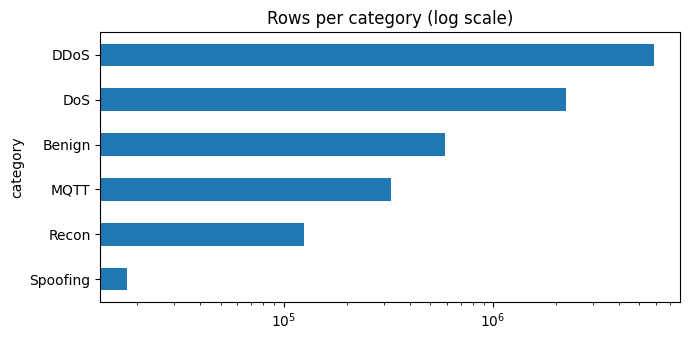

In [5]:
def normalize_type(s):
    """'TCP_IP-DDoS-UDP3_train.pcap.csv' -> 'TCP_IP-DDoS-UDP', 'Benign_test' -> 'Benign'"""
    s = str(s).strip()
    s = re.sub(r"(\.pcap)?(\.csv)?$", "", s, flags=re.I)
    s = re.sub(r"[_\- ]?(train|test)$", "", s, flags=re.I)
    s = re.sub(r"\d+$", "", s)
    s = s.strip("_- ")
    return "Benign" if "benign" in s.lower() else s

def category_of(t):
    t = t.lower()
    if "benign" in t: return "Benign"
    if "mqtt" in t: return "MQTT"
    if "arp" in t or "spoof" in t: return "Spoofing"
    if "recon" in t or "scan" in t or "ping" in t: return "Recon"
    if "ddos" in t: return "DDoS"
    if "dos" in t: return "DoS"
    return "Other"

type_map = {raw: normalize_type(raw) for raw in uniques[LABEL_COL]}

counts = pd.DataFrame([{"raw": k, "n": v} for k, v in uniques[LABEL_COL].items()])
counts["type"] = counts["raw"].map(type_map)
if SPLIT_COL:
    grp = (pq.read_table(PARQUET_PATH, columns=[LABEL_COL, SPLIT_COL])
             .group_by([LABEL_COL, SPLIT_COL]).aggregate([(LABEL_COL, "count")]).to_pandas())
    grp = grp.rename(columns={LABEL_COL: "raw", SPLIT_COL: "split", f"{LABEL_COL}_count": "n"})[["raw", "split", "n"]]
    grp["split"] = norm_split(grp["split"])
    grp["type"] = grp["raw"].map(type_map)
    counts = grp
else:
    counts["split"] = "all"

type_counts = counts.groupby(["split", "type"])["n"].sum().unstack(0).fillna(0).astype(int)
type_counts["category"] = [category_of(t) for t in type_counts.index]
print(type_counts.sort_values("category").to_string())

cat_counts = counts.assign(category=counts["type"].map(category_of)).groupby("category")["n"].sum().sort_values()
cat_counts.plot.barh(figsize=(7, 3.5), logx=True, title="Rows per category (log scale)")
plt.tight_layout(); plt.savefig(os.path.join(DATA_DIR, "figures", "eda_categories.png"), dpi=120); plt.show()

## 4. Stratified sampling
The file is read in batches so the full 9M rows never sit in memory.

**Profiling traffic is excluded.** Profiling was recorded in separate experiments (single devices powering on, an idle lab overnight, researchers interacting with devices), while the benign traffic in the test set was recorded during the attack scenarios. Including it raised the false alarm rate of the PCA baseline from 0.4% to about 8%, so training uses only benign traffic from the original train split (`PROFILING_AS_TRAIN = False`).

In [6]:
OVERSAMPLE = 1.3   # extra margin for cleaning and deduplication
targets = {}
for (split, t), n in counts.groupby(["split", "type"])["n"].sum().items():
    if split == "skip":
        want = 0
    elif t == "Benign":
        if split == "all":     want = N_TRAIN + N_VAL + N_TEST_BENIGN
        elif split == "train": want = N_TRAIN + N_VAL
        else:                  want = N_TEST_BENIGN
    else:
        want = 0 if split == "train" else ATTACK_PER_TYPE   # attacks are only needed for test
    targets[(split, t)] = min(1.0, want * OVERSAMPLE / max(n, 1))

read_cols = FEATURES_ALL + [LABEL_COL] + ([SPLIT_COL] if SPLIT_COL else [])
parts = []
for i, batch in enumerate(pf.iter_batches(batch_size=500_000, columns=read_cols)):
    b = batch.to_pandas()
    t = b[LABEL_COL].astype(str).map(type_map)
    sp = norm_split(b[SPLIT_COL]) if SPLIT_COL else pd.Series("all", index=b.index)
    p = pd.Series(list(zip(sp, t)), index=b.index).map(targets).fillna(0).values
    keep = rng.random(len(b)) < p
    sub = b.loc[keep, FEATURES_ALL].copy()
    sub["type"] = t[keep].values
    sub["split"] = sp[keep].values
    parts.append(sub)
    print(f"\rbatch {i+1}: sampled {sum(len(x) for x in parts):,}", end="")

df = pd.concat(parts, ignore_index=True); del parts
df["category"] = df["type"].map(category_of)
print(f"\nSample: {df.shape}")
print(df["category"].value_counts().to_string())

batch 19: sampled 237,260
Sample: (237260, 49)
category
Benign      230339
MQTT          2007
DDoS          1560
DoS           1534
Recon         1416
Spoofing       404


## 5. Cleaning and splitting

In [7]:
n0 = len(df)
df[FEATURES_ALL] = df[FEATURES_ALL].replace([np.inf, -np.inf], np.nan)
df = df.dropna(subset=FEATURES_ALL)
n1 = len(df)
# drop duplicates so the same row can't appear in both train and test (keep the test copy)
df = df.sort_values("split", key=lambda s: s.ne("test"), kind="stable")
df = df.drop_duplicates(subset=FEATURES_ALL + ["type"])
n2 = len(df)
print(f"Removed NaN/inf: {n0-n1:,} | removed duplicates: {n1-n2:,} | remaining: {n2:,}")

def take(frame, n, what):
    if len(frame) < n:
        print(f"Warning: only {len(frame):,} rows available for {what} (wanted {n:,})")
    return frame.sample(n=min(n, len(frame)), random_state=SEED)

benign = df[df["type"] == "Benign"]
attacks = df[df["type"] != "Benign"]
if SPLIT_COL:
    b_tr = benign[benign["split"] == "train"]
    b_te = benign[benign["split"] == "test"]
    attacks = attacks[attacks["split"] == "test"]
else:
    b_te = take(benign, N_TEST_BENIGN, "benign test")
    b_tr = benign.drop(b_te.index)

b_tr = take(b_tr, N_TRAIN + N_VAL, "benign train+val")
n_val = N_VAL if len(b_tr) >= N_TRAIN + N_VAL else int(len(b_tr) * N_VAL / (N_TRAIN + N_VAL))
val_df, train_df = b_tr.iloc[:n_val], b_tr.iloc[n_val:]
test_b = take(b_te, N_TEST_BENIGN, "benign test")
test_a = attacks.sample(frac=1, random_state=SEED).groupby("type").head(ATTACK_PER_TYPE)
test_df = pd.concat([test_b, test_a]).sample(frac=1, random_state=SEED)
assert len(test_b) and len(test_a) and len(val_df), "test set needs both benign and attack samples"

print(f"\ntrain: {len(train_df):,} | val: {len(val_df):,} | test: {len(test_df):,} "
      f"(attacks: {(test_df['type'] != 'Benign').mean():.1%})")
print("\nTest set composition:")
print(test_df["type"].value_counts().to_string())

Removed NaN/inf: 0 | removed duplicates: 0 | remaining: 237,260

train: 150,000 | val: 30,000 | test: 42,893 (attacks: 12.3%)

Test set composition:
type
Benign                     37607
DoS TCP Flood                300
MQTT DoS Connect Flood       300
DDoS SYN Flood               300
MQTT DDoS Publish Flood      300
MQTT DoS Publish Flood       300
DoS UDP Flood                300
Recon PortScan               300
ARP Spoofing                 300
Recon VulScan                300
DDoS UDP Flood               300
MQTT Malformed Data          300
MQTT DDoS Connect Flood      300
DoS ICMP Flood               300
DDoS ICMP Flood              300
Recon OSScan                 300
DDoS TCP Flood               300
DoS SYN Flood                300
Recon PingSweep              186


## 6. Feature selection and leakage check
- Drop constant and duplicated columns (e.g. `srate` is identical to `rate`).
- Single-feature ROC-AUC: a feature that separates attacks almost perfectly on its own is suspicious and may be an artifact of how the data was collected. This is a diagnostic only, it is not used for training.

Constant columns: ['drate', 'time_to_live']
Duplicate columns: ['srate', 'smtp', 'irc', 'llc']

Top 10 features by single-feature AUC:
        feature  single_feature_auc
  header_length               0.899
      rst_count               0.893
       variance               0.794
psh_flag_number               0.793
       magnitue               0.788
       tot_size               0.787
            max               0.787
            avg               0.787
            min               0.771
ack_flag_number               0.760

Final number of features: 40


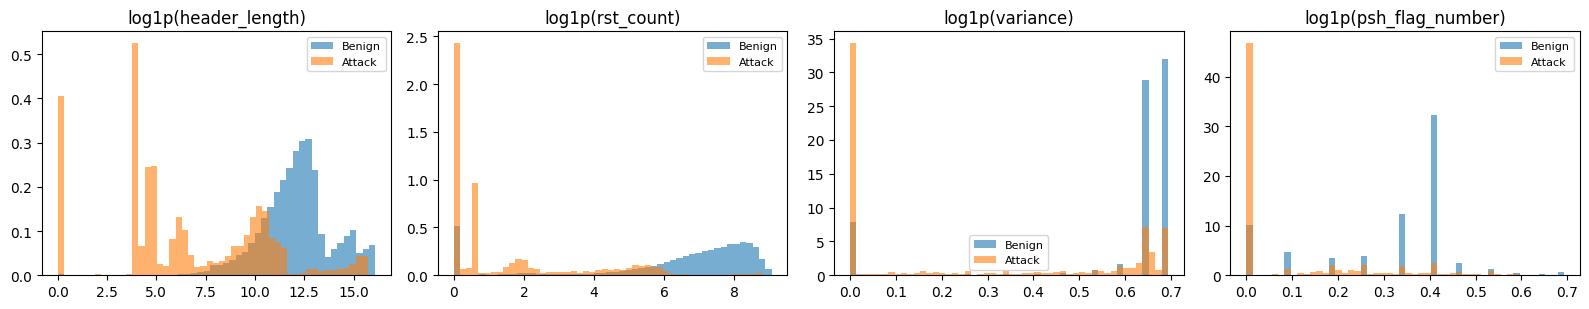

In [8]:
from sklearn.metrics import roc_auc_score

zero_var = [c for c in FEATURES_ALL if df[c].nunique() <= 1]
dup_cols, seen = [], {}
for c in FEATURES_ALL:
    if c in zero_var: continue
    key = pd.util.hash_pandas_object(train_df[c], index=False).sum()
    if key in seen and train_df[c].equals(train_df[seen[key]]):
        dup_cols.append(c)
    else:
        seen[key] = c
print("Constant columns:", zero_var)
print("Duplicate columns:", dup_cols)

y_te = (test_df["type"] != "Benign").astype(int).values
diag = []
for c in FEATURES_ALL:
    if c in zero_var: continue
    a = roc_auc_score(y_te, test_df[c].values)
    diag.append((c, max(a, 1 - a)))
diag = pd.DataFrame(diag, columns=["feature", "single_feature_auc"]).sort_values("single_feature_auc", ascending=False)
print("\nTop 10 features by single-feature AUC:")
print(diag.head(10).to_string(index=False, float_format="{:.3f}".format))

drop_manual = [c for c in FEATURES_ALL if c.lower() in {d.lower() for d in DROP_COLS}]
for c in drop_manual:
    if c in diag["feature"].values:
        print(f"\n{c}: single-feature AUC = {diag.set_index('feature').loc[c, 'single_feature_auc']:.3f} -> dropped")

FEATURES = [c for c in FEATURES_ALL if c not in set(zero_var) | set(dup_cols) | set(drop_manual)]
print(f"\nFinal number of features: {len(FEATURES)}")

top4 = [f for f in diag["feature"] if f in FEATURES][:4]
fig, axs = plt.subplots(1, 4, figsize=(16, 3.2))
for a, c in zip(axs, top4):
    for lab, m in [("Benign", y_te == 0), ("Attack", y_te == 1)]:
        a.hist(np.log1p(test_df[c].values[m].clip(min=0)), bins=50, alpha=.6, density=True, label=lab)
    a.set_title(f"log1p({c})"); a.legend(fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(DATA_DIR, "figures", "eda_top_features.png"), dpi=120); plt.show()

## 7. Log transform + scaling (fitted on train only)
Heavy-tailed columns (`header_length`, `rate`, `covariance`, ...) jump from 0 to millions, so they get `log1p` before scaling.

In [9]:
from sklearn.preprocessing import MinMaxScaler
import joblib

tr = train_df[FEATURES].astype("float64")
LOG_COLS = [c for c in FEATURES if tr[c].min() >= 0 and tr[c].max() > 100]
print("log1p columns:", LOG_COLS)

def transform(frame):
    X = frame[FEATURES].astype("float64").copy()
    for c in LOG_COLS:
        X[c] = np.log1p(X[c].clip(lower=0))
    return X.values

scaler = MinMaxScaler().fit(transform(train_df))
X_train = scaler.transform(transform(train_df)).astype("float32")
X_val   = scaler.transform(transform(val_df)).astype("float32")
X_test  = scaler.transform(transform(test_df)).astype("float32")
y_test  = y_te
attack_test   = test_df["type"].values.astype(str)
category_test = test_df["category"].values.astype(str)

print(f"X_train {X_train.shape}  range [{X_train.min():.2f}, {X_train.max():.2f}]")
print(f"X_test  {X_test.shape}  range [{X_test.min():.2f}, {X_test.max():.2f}]  (attacks can fall outside 0-1)")

log1p columns: ['header_length', 'duration', 'rate', 'rst_count', 'tot_sum', 'min', 'max', 'avg', 'std', 'tot_size', 'iat', 'radius', 'covariance', 'weight']
X_train (150000, 40)  range [0.00, 1.00]
X_test  (42893, 40)  range [-0.01, 8.00]  (attacks can fall outside 0-1)


## 8. Save

In [10]:
np.savez_compressed(os.path.join(DATA_DIR, "train.npz"), X=X_train)
np.savez_compressed(os.path.join(DATA_DIR, "val.npz"), X=X_val)
np.savez_compressed(os.path.join(DATA_DIR, "test.npz"), X=X_test, y=y_test,
                    attack_type=attack_test, category=category_test)
joblib.dump(scaler, os.path.join(DATA_DIR, "scaler.pkl"))

config = {
    "source": "CICIoMT2024 cleaned (Zenodo record 19452870), wifi_mqtt_clean.parquet",
    "seed": SEED,
    "label_col": LABEL_COL, "split_col": SPLIT_COL,
    "features": FEATURES, "log_cols": LOG_COLS,
    "profiling_as_train": PROFILING_AS_TRAIN,
    "dropped": {"manual": drop_manual, "zero_variance": zero_var, "duplicate": dup_cols},
    "sizes": {"train": len(X_train), "val": len(X_val), "test": len(X_test),
              "test_attacks": int(y_test.sum())},
    "attack_types": sorted(set(attack_test) - {"Benign"}),
    "threshold_rule": "99th percentile of validation (benign) scores",
}
with open(os.path.join(DATA_DIR, "config.json"), "w", encoding="utf-8") as f:
    json.dump(config, f, indent=2)

for fn in ["train.npz", "val.npz", "test.npz", "scaler.pkl", "config.json"]:
    print(f"{fn:12} {os.path.getsize(os.path.join(DATA_DIR, fn))/1e6:7.1f} MB")

train.npz        6.2 MB
val.npz          1.3 MB
test.npz         1.8 MB
scaler.pkl       0.0 MB
config.json      0.0 MB
